# Member 2 – Simple Hourly Forecast with Prediction Intervals
Put this notebook in the same folder as `hourly_patient_counts.csv`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize':(12,4),'axes.spines.top':False,'axes.spines.right':False})

## 1. Load data (Sep 2025 onward, drop the partial last day)

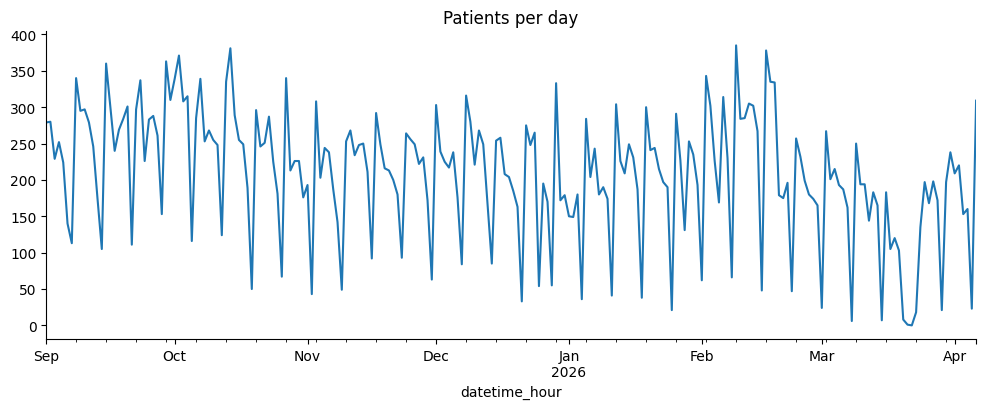

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 1200x400 with 0 Axes>

In [16]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('hourly_patient_counts.csv', parse_dates=['datetime_hour']).set_index('datetime_hour')
series = df['patient_count'].asfreq('h').fillna(0)['2025-09-01':'2026-04-06 23:00']
series.resample('D').sum().plot(title='Patients per day'); plt.show()
plt.savefig("graph1_daily_patients.png", dpi=300, bbox_inches="tight")
files.download("graph1_daily_patients.png")

## 2. Features (all at least 1 week old → a real 1-week-ahead forecast)

In [3]:
X = pd.DataFrame(index=series.index)
X['lag_168'] = series.shift(168)      # same hour last week
X['lag_336'] = series.shift(336)      # 2 weeks ago
X['lag_504'] = series.shift(504)      # 3 weeks ago
X['hour'] = X.index.hour
X['day_of_week'] = X.index.dayofweek
data = X.assign(actual=series).dropna()

## 3. Split by time: last 28 days = test, the 28 days before = calibration

In [4]:
test_start = series.index[-28*24]
cal_start  = test_start - pd.Timedelta(days=28)
train = data[data.index < cal_start]
cal   = data[(data.index >= cal_start) & (data.index < test_start)]
test  = data[data.index >= test_start]
feats = [c for c in data.columns if c != 'actual']
print(len(train), len(cal), len(test))

3384 672 672


## 4. Baselines and models

In [5]:
y = test['actual']
pred = {}
pred['Same hour last week'] = test['lag_168']
pred['3-week average'] = test[['lag_168','lag_336','lag_504']].mean(axis=1)

# SARIMAX (daily pattern, 24 h)
sx = SARIMAX(series[series.index < test_start], order=(1,0,1), seasonal_order=(1,0,1,24)).fit(disp=False, maxiter=50)
fc = sx.get_forecast(len(y)); pred['SARIMAX'] = pd.Series(fc.predicted_mean.values, index=y.index).clip(lower=0)
sx_ci = fc.conf_int(alpha=0.10); sx_lo = pd.Series(sx_ci.iloc[:,0].values, index=y.index).clip(lower=0); sx_hi = pd.Series(sx_ci.iloc[:,1].values, index=y.index)

# Random Forest
rf = RandomForestRegressor(n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(pd.concat([train, cal])[feats], pd.concat([train, cal])['actual'])
pred['Random Forest'] = pd.Series(rf.predict(test[feats]), index=y.index)

## 5. Prediction interval for Random Forest (90%)
We measure the model's typical error on the calibration weeks, separately for each hour of day, then add/subtract it from the forecast.

In [6]:
rf_cal = RandomForestRegressor(n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(train[feats], train['actual'])
cal_err = (cal['actual'] - rf_cal.predict(cal[feats]))
lo_q = cal_err.groupby(cal.index.hour).quantile(0.05)     # lower error per hour
hi_q = cal_err.groupby(cal.index.hour).quantile(0.95)     # upper error per hour
rf_lo = (pred['Random Forest'] + test.index.hour.map(lo_q).values).clip(lower=0)
rf_hi = (pred['Random Forest'] + test.index.hour.map(hi_q).values).clip(lower=0)

## 6. Evaluation table

In [7]:
def cov(lo, hi): return round(((y>=lo)&(y<=hi)).mean()*100, 1)
rows = []
for name, p in pred.items():
    rows.append({'Model':name, 'MAE':round(mean_absolute_error(y,p),2), 'RMSE':round(np.sqrt(mean_squared_error(y,p)),2),
                 'Interval coverage %': cov(rf_lo,rf_hi) if name=='Random Forest' else cov(sx_lo,sx_hi) if name=='SARIMAX' else None})
results = pd.DataFrame(rows).sort_values('MAE'); results.to_csv('model_comparison.csv', index=False); results

,Model,MAE,RMSE,Interval coverage %
3,Random Forest,3.77,6.66,80.1
0,Same hour last week,3.93,7.36,NaN
1,3-week average,3.94,7.13,NaN
2,SARIMAX,4.44,7.26,89.1


## 7. Visualizations

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 1200x400 with 0 Axes>

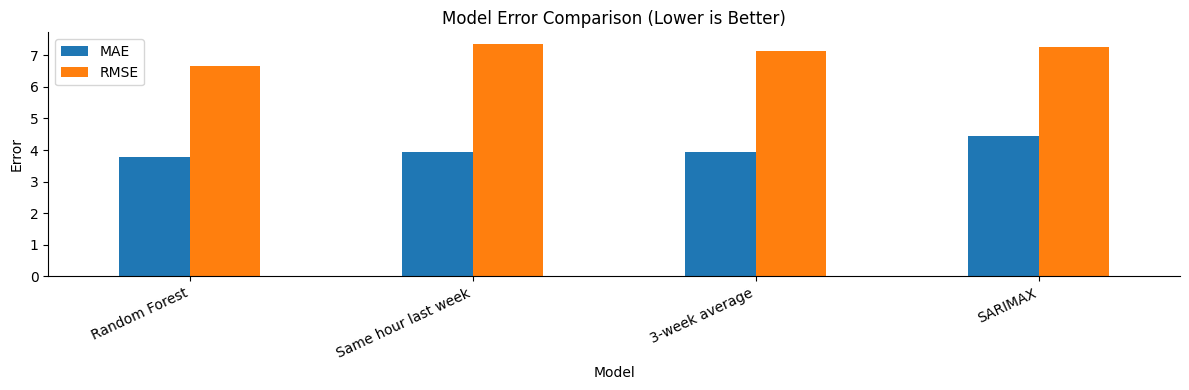

In [17]:
# Model Error Comparison Graph

plt.figure()

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    title="Model Error Comparison (Lower is Better)"
)

plt.ylabel("Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

# Save the graph
plt.savefig(
    "graph2_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# Download the graph to your computer
files.download("graph2_model_comparison.png")

plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

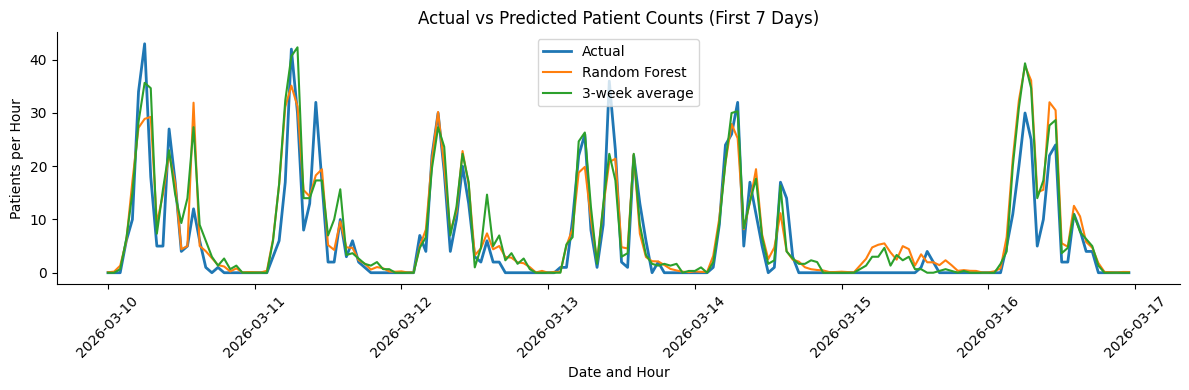

In [19]:
# Select the first 7 days (7 x 24 = 168 hours)
first_week = y.index[:7 * 24]

plt.figure()

# Plot actual patient counts
plt.plot(
    first_week,
    y.loc[first_week],
    label="Actual",
    linewidth=2
)

# Plot Random Forest predictions
plt.plot(
    first_week,
    pred["Random Forest"].loc[first_week],
    label="Random Forest"
)

# Plot 3-week average predictions
plt.plot(
    first_week,
    pred["3-week average"].loc[first_week],
    label="3-week average"
)

plt.title("Actual vs Predicted Patient Counts (First 7 Days)")
plt.xlabel("Date and Hour")
plt.ylabel("Patients per Hour")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

# Save visualization
plt.savefig(
    "graph3_actual_vs_predicted_first7days.png",
    dpi=300,
    bbox_inches="tight"
)

# Download to computer
files.download("graph3_actual_vs_predicted_first7days.png")

plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

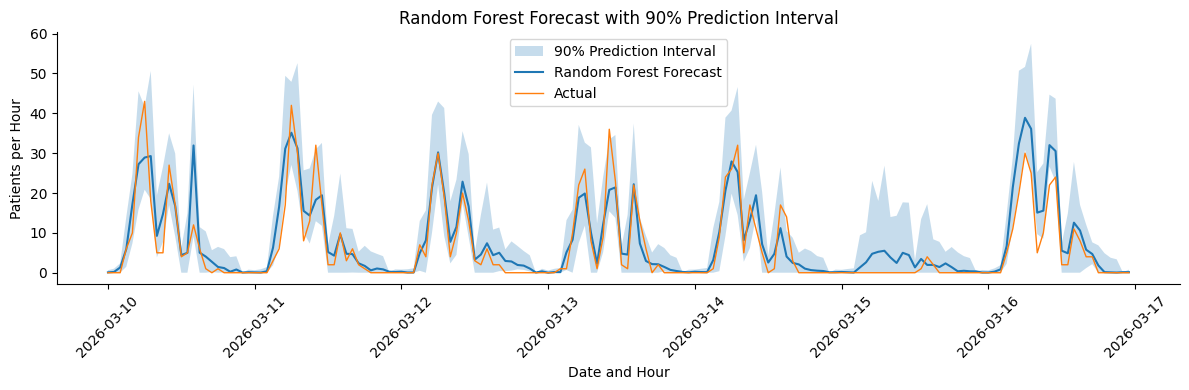

In [21]:
# Select the first 7 days (168 hours)
first_week = y.index[:7 * 24]

plt.figure()

# Show the 90% prediction interval (shaded area)
plt.fill_between(
    first_week,
    rf_lo.loc[first_week],
    rf_hi.loc[first_week],
    alpha=0.25,
    label="90% Prediction Interval"
)

# Plot Random Forest predictions
plt.plot(
    first_week,
    pred["Random Forest"].loc[first_week],
    label="Random Forest Forecast"
)

# Plot actual patient counts
plt.plot(
    first_week,
    y.loc[first_week],
    label="Actual",
    linewidth=1
)

plt.title("Random Forest Forecast with 90% Prediction Interval")
plt.xlabel("Date and Hour")
plt.ylabel("Patients per Hour")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()

# Save the graph
plt.savefig(
    "graph4_random_forest_prediction_interval.png",
    dpi=300,
    bbox_inches="tight"
)

# Download the image to your computer
files.download("graph4_random_forest_prediction_interval.png")

plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

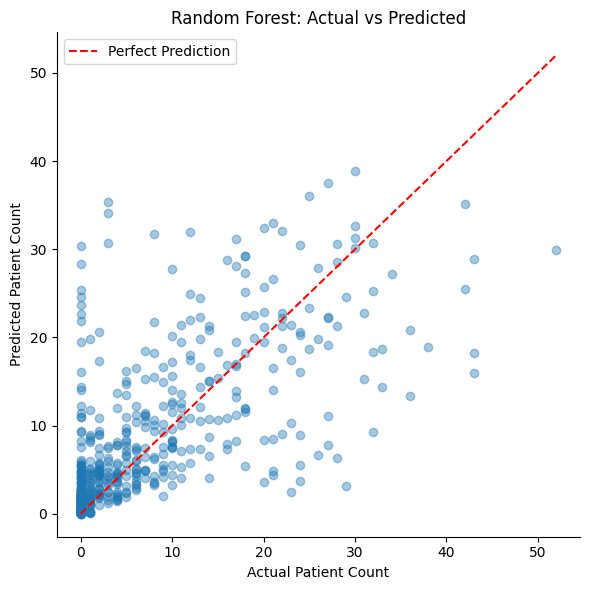

In [23]:
# Create scatter plot
plt.figure(figsize=(6, 6))

# Plot actual vs predicted values
plt.scatter(
    y,
    pred["Random Forest"],
    alpha=0.4
)

# Draw a reference line (perfect prediction)
maximum_value = max(
    y.max(),
    pred["Random Forest"].max()
)

plt.plot(
    [0, maximum_value],
    [0, maximum_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Patient Count")
plt.ylabel("Predicted Patient Count")
plt.title("Random Forest: Actual vs Predicted")

plt.legend()
plt.tight_layout()

# Save the graph
plt.savefig(
    "graph5_actual_vs_predicted_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

# Download the image to your computer
files.download("graph5_actual_vs_predicted_scatter.png")

plt.show()

## 8. Save for Member 3

In [9]:
out = pd.DataFrame({'datetime_hour':y.index, 'actual':y.values, 'predicted':pred['Random Forest'].round(2).values,
                    'lower':rf_lo.round(2).values, 'upper':rf_hi.round(2).values})
out.to_csv('forecast_with_intervals.csv', index=False); out.head()

,datetime_hour,actual,predicted,lower,upper
0,2026-03-10 00:00:00,0,0.09,0.00,0.63
1,2026-03-10 01:00:00,0,0.20,0.00,1.02
2,2026-03-10 02:00:00,0,1.32,0.00,2.37
3,2026-03-10 03:00:00,6,5.94,1.49,13.98
4,2026-03-10 04:00:00,10,17.20,7.36,24.74
